In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd

sns.set_style("ticks")
sns.set_context("talk")

In [2]:
omega = 9.5e-3  # rad/s
amu = 1.66e-27  # kg
boltzmann = 1.38064852e-23

# sound of speed in mars
gamma = 5 / 3
R = 8.314  # J/mol/K
T = 270  # K
g = 3.51  # m/s^2
sigma = 4.5e-16 * 1e-4  # m^2

# molecualr weight of atomic oxygen
M = 16  # g/mol
num_dens = 1e16  # Oxygen / m^3
R_prime = R / M * 1e3  # J/kg/K

# mass of oxygen atom
m = M * amu  # kg

# adiabatic sound speed
c = np.sqrt(gamma * R_prime * T)  # m/s

H = R_prime * T / g

# steady-state exobase altitude
z_exo = H * np.log(2**0.5 * num_dens * sigma * H)

# acoustic  frequency
omega_a = (gamma / 2) * (g / c)

kz_1D = np.sqrt((omega / c) ** 2 * (1 - (omega_a / omega) ** 2))
print(f"Speed of sound = {c:.2f} m/s")
print(f"Acoustic frequency = {omega_a:.3e} rad/s")
print("kz_1D =", kz_1D, "1/m")
print(f"lambda_z = {2 * np.pi / kz_1D / 1e3:.2f} km")
print(f"Scale height = {H / 1e3:.2f} km")
print(f"Exobase altitude = {z_exo / 1e3:.2f} km")

Speed of sound = 483.56 m/s
Acoustic frequency = 6.049e-03 rad/s
kz_1D = 1.514881164133759e-05 1/m
lambda_z = 414.76 km
Scale height = 39.97 km
Exobase altitude = 129.36 km


In [3]:
# in this case we can get AW in 2D if the following conditions are met:
print("AW in 2D if either of the following conditions are met:")
print(f"kx < {omega / c:.3e}")
print(f"lambda_x > {2 * np.pi * c / omega:.3e}")

AW in 2D if either of the following conditions are met:
kx < 1.965e-05
lambda_x > 3.198e+05


In [4]:
omega = 9.5e-3  # rad/s
amu = 1.66e-27  # kg
boltzmann = 1.38064852e-23

# sound of speed in mars
gamma = 5 / 3
R = 8.314  # J/mol/K
T = 270  # K
g = 3.51  # m/s^2
# sigma = 4.5e-16 * 1e-4 # m^2
ref_diam = 2.92e-10
sigma = np.pi * ref_diam**2

# molecualr weight of molecular hydrogen
M = 2  # g/mol
num_dens = 1e14  # Oxygen / m^3
R_prime = R / M * 1e3  # J/kg/K

# mass of oxygen atom
m = M * amu  # kg

# adiabatic sound speed
c = np.sqrt(gamma * R_prime * T)  # m/s

H = R_prime * T / g

# steady-state exobase altitude
z_exo = H * np.log(2**0.5 * num_dens * sigma * H)

# acoustic  frequency
omega_a = (gamma / 2) * (g / c)

kz_1D = np.sqrt((omega / c) ** 2 * (1 - (omega_a / omega) ** 2))
print(f"Speed of sound = {c:.2f} m/s")
print(f"Acoustic frequency = {omega_a:.3e} rad/s")
print("kz_1D =", kz_1D, "1/m")
print(f"lambda_z = {2 * np.pi / kz_1D / 1e3:.2f} km")
print(f"Height of scale height = {H / 1e3:.2f} km")
print(f"Exobase altitude = {z_exo / 1e3:.2f} km")

Speed of sound = 1367.72 m/s
Acoustic frequency = 2.139e-03 rad/s
kz_1D = 6.767594182590456e-06 1/m
lambda_z = 928.42 km
Height of scale height = 319.77 km
Exobase altitude = 797.61 km


<>:19: SyntaxWarning: invalid escape sequence '\o'
<>:19: SyntaxWarning: invalid escape sequence '\o'
/tmp/ipykernel_62292/704623162.py:19: SyntaxWarning: invalid escape sequence '\o'
  ax1.axvline(omega, color="k", linestyle="--", alpha=0.5, label="$\omega$ = 9.5e-3")


Text(0.5, 1.0, 'Dispersion Relation')

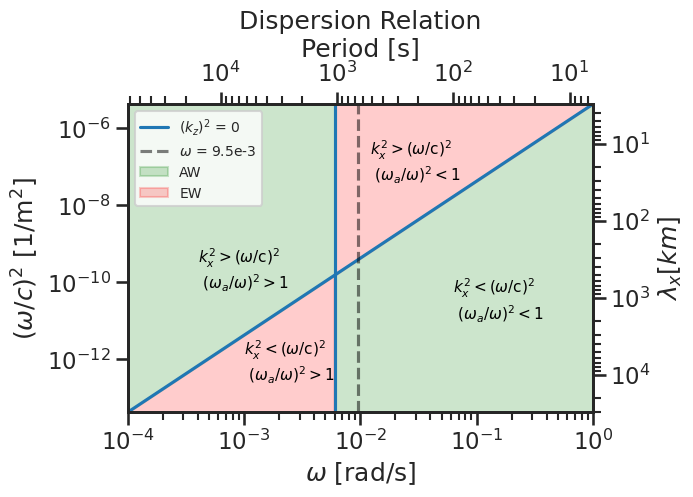

In [4]:
# omega_array = np.linspace(1e-4, 1.0, 1000)
omega_array = np.logspace(-4, 0, 1000)

kx_cond = (omega_array / c) ** 2
bouyancy_cond = (omega_a / omega_array) ** 2

# Create the first plot with the current y-axis data
(
    fig,
    ax1,
) = plt.subplots(figsize=(6, 4))

where = bouyancy_cond < 1
ax1.loglog(omega_array, kx_cond, label=r"$(k_z)^2$ = 0", color="C0")
ax1.set_xlabel(r"$\omega$ [rad/s]")
ax1.set_ylabel(r"$(\omega / c)^2$ [1/m$^2$]")

# draw vertical line at 2 pi / omega
ax1.axvline(omega, color="k", linestyle="--", alpha=0.5, label="$\omega$ = 9.5e-3")

# remove margins
ax1.margins(0)

# get y axis limits
ymin, ymax = ax1.get_ylim()
# get x axis limits
xmin, xmax = ax1.get_xlim()

# fill area under curve
ax1.fill_between(omega_array, 0, kx_cond, where=where, alpha=0.2, color="g", label="AW")

# fill area above curve
ax1.fill_between(omega_array, kx_cond, ymax, where=where, alpha=0.2, color="r", label="EW")

# Create the second plot with the second y-axis
ax2 = ax1.twinx()
ax2.set_yscale("log")

ax3 = ax1.twiny()
ax3.set_xscale("log")

# apply function and set transformed values to right axis limits
ax2.set_ylim(2 * np.pi / np.sqrt(ymin) / 1e3, 2 * np.pi / np.sqrt(ymax) / 1e3)

# apply function and set transformed values to top axis limits
ax3.set_xlim(2 * np.pi / xmin, 2 * np.pi / xmax)

# ax2.plot(omega_array, 2 * np.pi * c / omega_array, label=r'$\lambda_x$')
ax2.set_ylabel(r"$\lambda_x [km]$")

ax3.set_xlabel(r"Period [s]")


# fill area above curve where bouyancy_cond > 1
where = bouyancy_cond > 1
ax1.fill_between(omega_array, kx_cond, ymax, where=where, alpha=0.2, color="g")

# fill area under curve where bouyancy_cond > 1
ax1.fill_between(omega_array, 0, kx_cond, where=where, alpha=0.2, color="r")

ax1.text(
    0.7,
    0.3,
    "$k_x^2 < (\\omega / \\rm c)^2$ \n $(\\omega_a / \\omega)^2 < 1$",
    fontsize=11,
    color="k",
    transform=ax1.transAxes,
)
ax1.text(
    0.25,
    0.1,
    "$k_x^2 < (\\omega / \\rm c)^2$ \n $(\\omega_a / \\omega)^2 > 1$",
    fontsize=11,
    color="k",
    transform=ax1.transAxes,
)
ax1.text(
    0.15,
    0.4,
    "$k_x^2 > (\\omega / \\rm c)^2$ \n $(\\omega_a / \\omega)^2 > 1$",
    fontsize=11,
    color="k",
    transform=ax1.transAxes,
)
ax1.text(
    0.52,
    0.75,
    "$k_x^2 > (\\omega / \\rm c)^2$ \n $(\\omega_a / \\omega)^2 < 1$",
    fontsize=11,
    color="k",
    transform=ax1.transAxes,
)

ax1.axvline(omega_a, color="C0")

ax1.legend(fontsize=10, loc="upper left")

ax1.set_title("Dispersion Relation")

# fig.savefig('dispersion_relation.png', dpi=300, bbox_inches='tight')

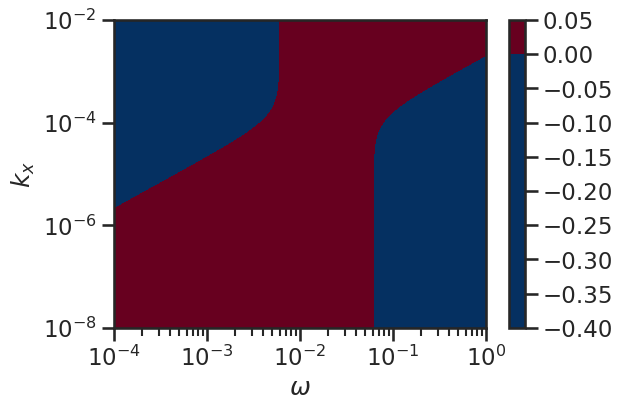

In [5]:
# kx_range = np.linspace(2 * np.pi / 1e4, 2 * np.pi / 1e7, 1000)
# omega_range = np.linspace(1e-6, 1e-1, 1000)

kx_range = np.logspace(-8, -2, 1000)
omega_range = np.logspace(-4, 0, 1000)

KX, OMEGA = np.meshgrid(kx_range, omega_range)

lambda_z = 50e3
KZ = 2 * np.pi / lambda_z
ROOTS = KZ**2 - (-(KX**2) + (OMEGA / c) ** 2) * (1 - (omega_a / OMEGA) ** 2)

# draw contours of the dispersion relation (ROOTS)
fig, ax = plt.subplots(figsize=(6, 4))
# ax.contour(OMEGA, KX, ROOTS, [0], colors='g')
ax.set_ylabel(r"$k_x$")
ax.set_xlabel(r"$\omega$")

# use contourf with OMEGA, KX, ROOTS, apply symlog norm
from matplotlib import colors

cs = ax.contourf(
    OMEGA, KX, ROOTS, cmap="RdBu_r", norm=colors.SymLogNorm(linthresh=1e-7, linscale=1e-7, vmin=-1e-7, vmax=1e-7)
)
fig.colorbar(cs, ax=ax, extend="both")

# CS2 = ax.contour(cs, levels=cs.levels[::2], colors='g')


# scale both axes logarithmically
ax.set_yscale("log")
ax.set_xscale("log")

# k1d = omega_range / c
# ax.plot(omega_range, k1d, 'k--')
# ax.axvline(omega_a, color='k', ls='--')


# where = bouyancy_cond < 1
# ax.fill_between(omega_array, kx_cond, ymax, where=where, alpha=0.2, color='g')

<>:36: SyntaxWarning: invalid escape sequence '\l'
<>:36: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_62292/127865069.py:36: SyntaxWarning: invalid escape sequence '\l'
  ax.set_title("Dispersion relation roots for $\lambda_z = 50$km")


Text(0.5, 1.0, 'Dispersion relation roots for $\\lambda_z = 50$km')

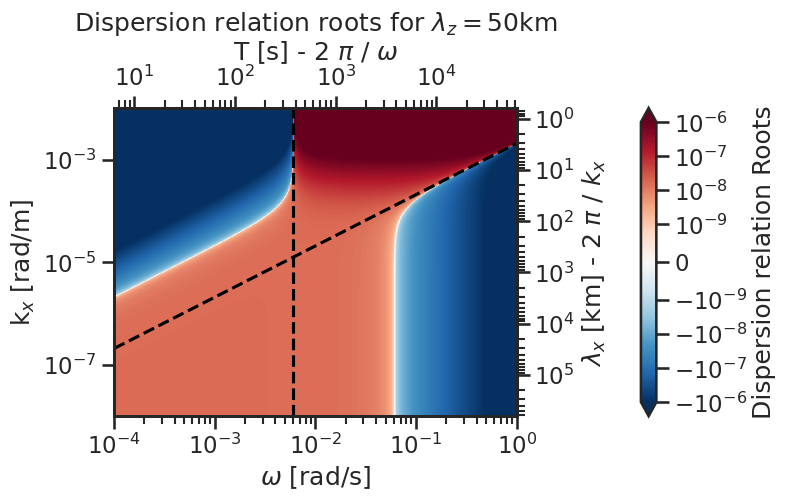

In [6]:
from matplotlib import colors

# draw pcolormesh of the dispersion relation (ROOTS)
fig, ax = plt.subplots(figsize=(8, 4))

pcm = ax.pcolormesh(OMEGA, KX, ROOTS, cmap="RdBu_r", norm=colors.SymLogNorm(1e-9, vmin=-1e-6, vmax=1e-6))

fig.colorbar(pcm, ax=ax, label="Dispersion relation Roots", extend="both", pad=0.2)

# twin vertical axes - convert kx to wavelength
ax2 = ax.twinx()
ax2.set_yscale("log")
kx_lims = ax.get_ylim()
ax.set_ylim(kx_lims)
ax2.set_ylim(2 * np.pi / kx_lims[0] / 1e3, 2 * np.pi / kx_lims[1] / 1e3)
ax2.set_ylabel(r"$\lambda_x$ [km] - 2 $\pi$ / $k_x$")

# twin horizontal axes - convert omega to period
ax3 = ax.twiny()
ax3.set_xscale("log")
omega_lims = ax.get_xlim()
ax3.set_xlim(2 * np.pi / omega_lims[1], 2 * np.pi / omega_lims[0])
ax3.set_xlabel(r"T [s] - 2 $\pi$ / $\omega$")

# set log axes
ax.set_xscale("log")
ax.set_yscale("log")

ax.set_ylabel(r"k$_x$ [rad/m]")
ax.set_xlabel(r"$\omega$ [rad/s]")

k1d = omega_range / c
ax.plot(omega_range, k1d, "k--")
ax.axvline(omega_a, color="k", ls="--")

ax.set_title("Dispersion relation roots for $\lambda_z = 50$km")

# fig.savefig('dispersion_relation_roots.png', dpi=300, bbox_inches='tight')

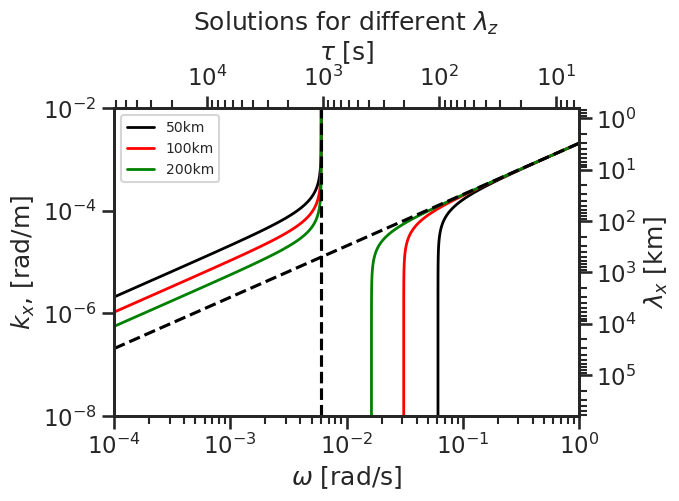

In [7]:
# kx_range = np.linspace(2 * np.pi / 1e4, 2 * np.pi / 1e7, 1000)
# omega_range = np.linspace(1e-6, 1e-1, 1000)

kx_range = np.logspace(-8, -2, 1000)
omega_range = np.logspace(-4, 0, 1000)

KX, OMEGA = np.meshgrid(kx_range, omega_range)

fig, ax = plt.subplots(figsize=(6, 4))
ax.set_ylabel(r"$k_x$, [rad/m]")
ax.set_xlabel(r"$\omega$ [rad/s]")

ax.set_yscale("log")
ax.set_xscale("log")

lambdas = [50e3, 100e3, 200e3]
colors = ["k", "r", "g", "b", "m", "c"]
for lambda_z, color in zip(lambdas, colors):
    # for lambda_z in [50e3, 100e3, 200e3, 300e3]:
    KZ = 2 * np.pi / lambda_z
    ROOTS = KZ**2 - (-(KX**2) + (OMEGA / c) ** 2) * (1 - (omega_a / OMEGA) ** 2)

    # draw contours of the dispersion relation (ROOTS)
    ax.contour(OMEGA, KX, ROOTS, [0], colors=color, linewidths=2, linestyles="solid")

    # make an empty line with same format
    ax.plot([], [], color=color, linewidth=2, label=rf"{int(lambda_z / 1e3)}km")


# twin vertical axes - convert kx to wavelength
ax2 = ax.twinx()
ax2.set_yscale("log")
kx_lims = ax.get_ylim()
ax.set_ylim(kx_lims)
ax2.set_ylim(2 * np.pi / kx_lims[0] / 1e3, 2 * np.pi / kx_lims[1] / 1e3)
ax2.set_ylabel(r"$\lambda_x$ [km]")

# twin horizontal axes - convert omega to period
ax3 = ax.twiny()
ax3.set_xscale("log")
omega_lims = ax.get_xlim()
ax3.set_xlim(2 * np.pi / omega_lims[0], 2 * np.pi / omega_lims[1])
ax3.set_xlabel(r"$\tau$ [s]")


# use contourf with OMEGA, KX, ROOTS, apply symlog norm
# from matplotlib import colors
# cs = ax.contourf(OMEGA, KX, ROOTS, cmap='RdBu_r',
#                  norm=colors.SymLogNorm(linthresh=1e-7, linscale=1e-7, vmin=-1e-7, vmax=1e-7))
# fig.colorbar(cs, ax=ax, extend='both')

# CS2 = ax.contour(cs, levels=cs.levels[::2], colors='g')


# scale both axes logarithmically
ax.legend(fontsize=10, loc="upper left")
# k1d = omega_range / c
# ax.plot(omega_range, k1d, 'k--')
# ax.axvline(omega_a, color='k', ls='--')

ax.set_title(r"Solutions for different $\lambda_z$")
k1d = omega_range / c
ax.plot(omega_range, k1d, "k--")
ax.axvline(omega_a, color="k", ls="--")

# draw horizontal line at lambda_x = 600km
# ax2.axhline(600, color='b', ls='--')
# ax2.axhline(1200, color='b', ls='--')
# ax.axvline(6.1e-2, color='darkgrey', ls='--')


# where = bouyancy_cond < 1
# ax.fill_between(omega_array, kx_cond, ymax, where=where, alpha=0.2, color='g')

# fig.savefig('dispersion_relation_solutions.png', dpi=300, bbox_inches='tight')

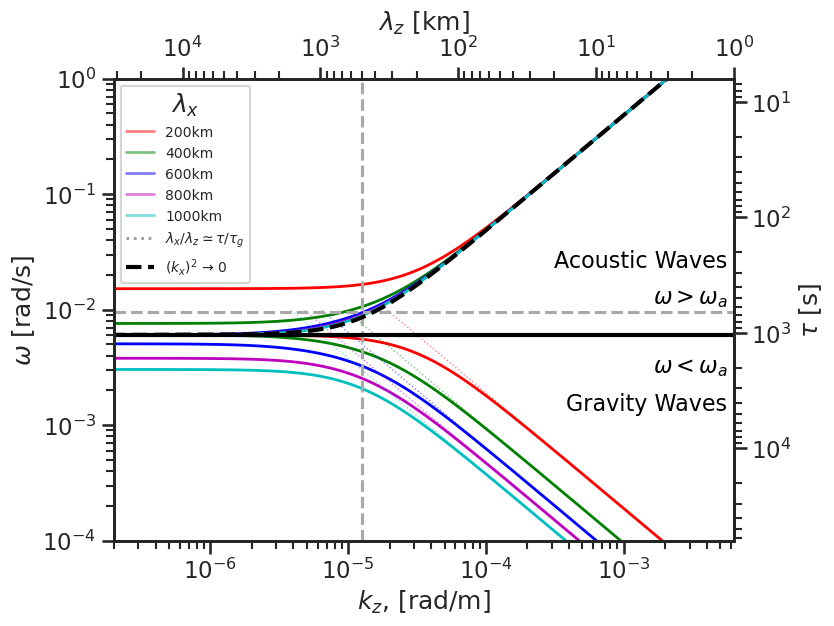

In [8]:
lambda_z_range = np.logspace(3, 7.5, 1000)
kz_range = 2 * np.pi / lambda_z_range[::-1]

omega_range = np.logspace(-4, 0, 1000)

KZ, OMEGA = np.meshgrid(kz_range, omega_range)

x_lambdas = [200e3, 400e3, 600e3, 800e3, 1000e3, 1200e3]
colors = ["r", "g", "b", "m", "c"]

fig, ax = plt.subplots(figsize=(8, 6))
ax.set_xlabel(r"$k_z$, [rad/m]")
ax.set_ylabel(r"$\omega$ [rad/s]")

# k1d = omega_range / c
# ax.plot(k1d, omega_range, 'k-', lw=3, zorder=10)
ax.axhline(omega_a, color="k", ls="-", zorder=10, lw=3)

ax.set_yscale("log")
ax.set_xscale("log")

for xlambda, color in zip(x_lambdas, colors):
    KX = 2 * np.pi / xlambda
    ROOTS = KX**2 - (OMEGA / c) ** 2 + KZ**2 / (1 - (omega_a / OMEGA) ** 2)

    ax.contour(KZ, OMEGA, ROOTS, [0], colors=color, linewidths=2, linestyles="solid")
    # make an empty line with same format
    ax.plot([], [], color=color, linewidth=2, alpha=0.5, label=rf"{int(xlambda / 1e3)}km")

    # ax.plot(np.sqrt((omega_range / c)**2 - (KX)**2), omega_range, 'k--', lw=3, zorder=10)

    _kz = KX * omega_a / omega_range[: omega_range.size // 2]
    ax.plot(_kz, omega_range[: omega_range.size // 2], color=color, linewidth=1, alpha=0.5, ls=":")

ax.plot([], [], color="k", linewidth=2, alpha=0.4, ls=":", label=r"$\lambda_x/\lambda_z \simeq \tau/\tau_g$")


# ax.axvspan(2 * np.pi / 50e3, 2*np.pi/30e3, color='b', alpha=0.2)

# ax.axhspan(5e-2, 1e-1, color='r', alpha=0.2)

ax.axvline(2 * np.pi / 500e3, color="darkgrey", ls="--")
# ax.axhline(6.1e-2, color='darkgrey', ls='--')
ax.axhline(9.5e-3, color="darkgrey", ls="--")

# ax.axhline(3e-4, color='darkgrey', ls='--')


# twin vertical axes - convert kx to wavelength
ax2 = ax.twiny()
ax2.set_xscale("log")
kz_lims = ax.get_xlim()
ax.set_xlim(kz_lims)
ax2.set_xlim(2 * np.pi / kz_lims[0] / 1e3, 2 * np.pi / kz_lims[1] / 1e3)
ax2.set_xlabel(r"$\lambda_z$ [km]")

# twin horizontal axes - convert omega to period
ax3 = ax.twinx()
ax3.set_yscale("log")
omega_lims = ax.get_ylim()
ax3.set_ylim(2 * np.pi / omega_lims[0], 2 * np.pi / omega_lims[1])
ax3.set_ylabel(r"$\tau$ [s]")


# ax2.axvline(50, color='red', ls='--')
ax.text(0.99, 0.58, "Acoustic Waves", fontsize=16, color="k", transform=ax.transAxes, ha="right", va="bottom")
ax.text(0.99, 0.5, r"$\omega > \omega_a$", fontsize=16, color="k", transform=ax.transAxes, ha="right", va="bottom")

ax.text(0.99, 0.4, r"$\omega < \omega_a $", fontsize=16, color="k", transform=ax.transAxes, ha="right", va="top")
ax.text(0.99, 0.32, "Gravity Waves", fontsize=16, color="k", transform=ax.transAxes, ha="right", va="top")

# ax.text(0.01, 0.3, 'Longer wavelengths', fontsize=16, color='k', transform=ax.transAxes, ha='left', va='bottom')
# ax.text(0.99, 0.2, 'Shorter wavelengths', fontsize=16, color='k', transform=ax.transAxes, ha='right', va='top')

# ax.text(0.3, 0.3, r'c$_z$ < c$_s$', fontsize=16, color='k', transform=ax.transAxes, ha='left', va='top')
# ax.text(0.5, 0.6, r'c$_z$ > c$_s$', fontsize=16, color='k', transform=ax.transAxes, ha='right', va='bottom')

# add text and rotate 45 deg
# text = ax.text(0.7, 0.85, '1D Approx', fontsize=16, color='k', transform=ax.transAxes, ha='center', va='center')
# text.set_rotation(32)

# kz_1D = np.sqrt((omega_range / c) ** 2 * (1 - (omega_a / omega_range) ** 2))
kz_squared = (omega_range / c) ** 2 * (1 - (omega_a / omega_range) ** 2)
kz_1D = np.sqrt(np.maximum(kz_squared, 0))
ax.plot(kz_1D, omega_range, "k--", lw=3, zorder=10, label=r"$(k_x)^2$ → 0")


ax.legend(fontsize=10, loc="upper left", title=r"$\lambda_x$")

In [ ]:
# FORMULA
    # KZ = 2 * np.pi / lambda_z
    # ROOTS = KZ**2 - (-(KX**2) + (OMEGA / c) ** 2) * (1 - (omega_a / OMEGA) ** 2)

# use scipy newton method to find the roots of the dispersion relation; for omega = 6.1e-2

# define the function to find the roots
def f(kz, omega=9.5e-3):
    return kz**2 - ( - (2 * np.pi / 600e3)**2 + (omega / c)**2) * (1 - (omega_a / omega)**2)

from scipy.optimize import newton

root = newton(f, 2 * np.pi / 50e3, maxiter=1000)
2 * np.pi / root / 1e3  # estimatad wavelength in km

np.float64(490.20951940476095)

In [20]:
root

NameError: name 'root' is not defined

In [13]:
6e-2 > omega_a

np.True_

In [14]:
2 * np.pi / 3.3e-3

1903.9955476301777

In [15]:
2 * np.pi / 1.9e-2 / 60

5.5115660589294615

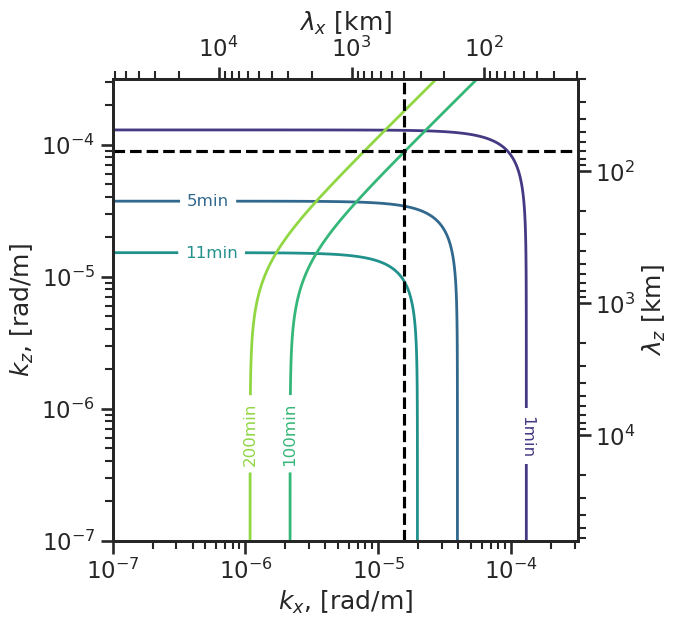

In [33]:
kz_range = np.logspace(-7, -3.5, 1000)
kx_range = np.logspace(-7, -3.5, 1000)

# kz_range = np.linspace(-1e-4, 1e-4, 1000)
# kx_range = np.linspace(-1e-4, 1e-4, 1000)


tau_range = [12000, 6000, 660, 330, 100][::-1]
# Get colors from sns color palette to pass to ax.contour
colors = sns.color_palette("viridis", len(tau_range))

# omega_range = 2 * np.pi / np.asarray(tau_range)

# LHS = (omega_range / c)**2 + (omega_a / omega_range)**2

KZ, KX = np.meshgrid(kz_range, kx_range)


fig, ax = plt.subplots(figsize=(6, 6))
ax.set_box_aspect(1)

ax.set_xlabel(r"$k_x$, [rad/m]")
ax.set_ylabel(r"$k_z$, [rad/m]")

ax.set_yscale("log")
ax.set_xscale("log")

for tau, color in zip(tau_range, colors):
    iomega = 2 * np.pi / tau
    ROOTS = KZ**2 - (-(KX**2) + (iomega / c) ** 2) * (1 - (omega_a / iomega) ** 2)

    cs = ax.contour(KX, KZ, ROOTS, [0], colors=[color], linewidths=2, linestyles="solid")

    clabels = ax.clabel(cs, [0], fmt=f"{tau // 60}min", fontsize=12, inline=False)
    # clabels = ax.clabel(cs, [0], fmt=f'{2 * np.pi / tau:.1e} rad/s', fontsize=12, inline=False)
    # # adjust the position of the labels
    for label in clabels:
        # label.get_bbox_patch().set_alpha(0.)
        label.set_bbox(dict(facecolor="white", edgecolor="none", pad=5))
        #     print(label.get_rotation())
        if label.get_rotation() < 350:
            label.set_position((label.get_position()[0], label.get_position()[1] + 5e-7))
        else:
            label.set_position((label.get_position()[0] + 4e-7, label.get_position()[1]))
    # ax.plot(np.sqrt((omega_range / c)**2 - (KX)**2), omega_range, 'k--', lw=3, zorder=10)

    # _kz = KX * omega_a / omega_range[:omega_range.size//2]
    # ax.plot(_kz, omega_range[:omega_range.size//2], color=color, linewidth=1, alpha=0.5, ls=':')


# twin vertical axes - convert kx to wavelength
ax2 = ax.twiny()
ax2.set_xscale("log")
kx_lims = ax.get_xlim()
ax.set_xlim(kx_lims)
ax2.set_xlim(2 * np.pi / kx_lims[0] / 1e3, 2 * np.pi / kx_lims[1] / 1e3)
ax2.set_xlabel(r"$\lambda_x$ [km]")

# twin vertical axes - convert kx to wavelength
ax3 = ax.twinx()
ax3.set_yscale("log")
kz_lims = ax.get_ylim()
ax.set_ylim(kz_lims)
ax3.set_ylim(2 * np.pi / kz_lims[0] / 1e3, 2 * np.pi / kz_lims[1] / 1e3)
ax3.set_ylabel(r"$\lambda_z$ [km]")


ax.axvline(2 * np.pi / 400e3, color='k', ls='--')
ax.axhline(2 * np.pi / 70e3, color='k', ls='--')

# ax.scatter([2 * np.pi / 600e3], [2 * np.pi / 50e3], color="k", marker="o", s=150, zorder=10)
# ax.scatter([2 * np.pi / 1000e3], [2 * np.pi / 169e3], color='darkorange', marker='o', s=150, zorder=10, edgecolor='k', linewidth=1)

# ax.axhline(2 * np.pi / 169e3, color='darkorange', ls='--')

# ROOTS = KZ**2 + (omega_a / c)**2 + KX**2
# cs = ax.contour(KX, KZ, ROOTS, LHS, linewidths=2, linestyles='solid')
# fmt_func = {x:lab for x,lab in zip(LHS, tau_range)}
# ax.clabel(cs, LHS, fmt=lambda x: fmt_func[x], fontsize=8)

# ax.legend(fontsize=9, loc='upper left', title=r'$\tau$')

In [38]:
ax.texts[0].get_bbox_patch()

In [ ]:
k1d = omega_range / c
ax.plot(k1d, omega_range, "k--")
ax.axhline(omega_a, color="k", ls="--")

lambdas = [50e3, 100e3, 200e3]
colors = ["k", "r", "g", "b", "m", "c"]
for lambda_z, color in zip(lambdas, colors):
    # for lambda_z in [50e3, 100e3, 200e3, 300e3]:
    KZ = 2 * np.pi / lambda_z
    ROOTS = KZ**2 - (-(KX**2) + (OMEGA / c) ** 2) * (1 - (omega_a / OMEGA) ** 2)

    # draw contours of the dispersion relation (ROOTS)
    ax.contour(KX, OMEGA, ROOTS, [0], colors=color, linewidths=2, linestyles="solid")

    # make an empty line with same format
    ax.plot([], [], color=color, linewidth=2, label=rf"{int(lambda_z / 1e3)}km")

# twin vertical axes - convert kx to wavelength
ax2 = ax.twiny()
ax2.set_xscale("log")
kx_lims = ax.get_xlim()
ax.set_xlim(kx_lims)
ax2.set_xlim(2 * np.pi / kx_lims[0] / 1e3, 2 * np.pi / kx_lims[1] / 1e3)
ax2.set_xlabel(r"$\lambda_x$ [km]")


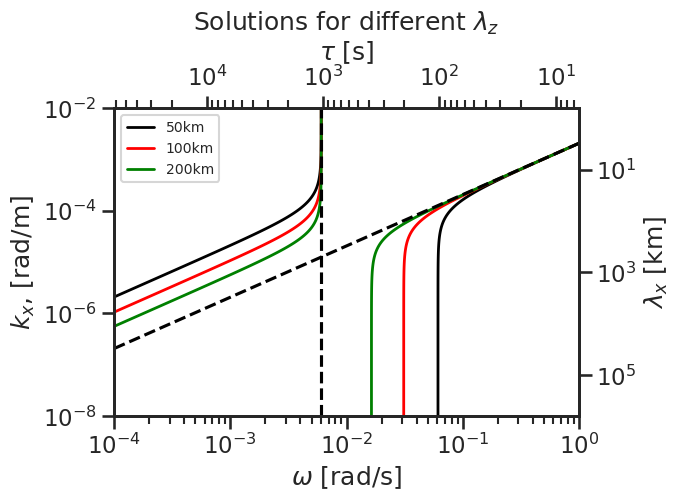

In [ ]:
# kx_range = np.linspace(2 * np.pi / 1e4, 2 * np.pi / 1e7, 1000)
# omega_range = np.linspace(1e-6, 1e-1, 1000)

kx_range = np.logspace(-8, -2, 1000)
omega_range = np.logspace(-4, 0, 1000)

KX, OMEGA = np.meshgrid(kx_range, omega_range)

fig, ax = plt.subplots(figsize=(6, 4))
ax.set_ylabel(r"$k_x$, [rad/m]")
ax.set_xlabel(r"$\omega$ [rad/s]")

ax.set_yscale("log")
ax.set_xscale("log")

lambdas = [50e3, 100e3, 200e3]
colors = ["k", "r", "g", "b", "m", "c"]
for lambda_z, color in zip(lambdas, colors):
    # for lambda_z in [50e3, 100e3, 200e3, 300e3]:
    KZ = 2 * np.pi / lambda_z
    ROOTS = KZ**2 - (-(KX**2) + (OMEGA / c) ** 2) * (1 - (omega_a / OMEGA) ** 2)

    # draw contours of the dispersion relation (ROOTS)
    ax.contour(OMEGA, KX, ROOTS, [0], colors=color, linewidths=2, linestyles="solid")

    # make an empty line with same format
    ax.plot([], [], color=color, linewidth=2, label=rf"{int(lambda_z / 1e3)}km")


# twin vertical axes - convert kx to wavelength
ax2 = ax.twinx()
ax2.set_yscale("log")
kx_lims = ax.get_ylim()
ax.set_ylim(kx_lims)
ax2.set_ylim(2 * np.pi / kx_lims[0] / 1e3, 2 * np.pi / kx_lims[1] / 1e3)
ax2.set_ylabel(r"$\lambda_x$ [km]")

# twin horizontal axes - convert omega to period
ax3 = ax.twiny()
ax3.set_xscale("log")
omega_lims = ax.get_xlim()
ax3.set_xlim(2 * np.pi / omega_lims[0], 2 * np.pi / omega_lims[1])
ax3.set_xlabel(r"$\tau$ [s]")


# use contourf with OMEGA, KX, ROOTS, apply symlog norm
# from matplotlib import colors
# cs = ax.contourf(OMEGA, KX, ROOTS, cmap='RdBu_r',
#                  norm=colors.SymLogNorm(linthresh=1e-7, linscale=1e-7, vmin=-1e-7, vmax=1e-7))
# fig.colorbar(cs, ax=ax, extend='both')

# CS2 = ax.contour(cs, levels=cs.levels[::2], colors='g')


# scale both axes logarithmically
ax.legend(fontsize=10, loc="upper left")
# k1d = omega_range / c
# ax.plot(omega_range, k1d, 'k--')
# ax.axvline(omega_a, color='k', ls='--')

ax.set_title("Solutions for different $\lambda_z$")

k1d = omega_range / c
ax.plot(omega_range, k1d, "k--")
ax.axvline(omega_a, color="k", ls="--")

# draw horizontal line at lambda_x = 600km
# ax2.axhline(600, color='b', ls='--')
# ax2.axhline(1200, color='b', ls='--')
# ax.axvline(6.1e-2, color='darkgrey', ls='--')


# where = bouyancy_cond < 1
# ax.fill_between(omega_array, kx_cond, ymax, where=where, alpha=0.2, color='g')

# fig.savefig('dispersion_relation_solutions.png', dpi=300, bbox_inches='tight')

In [ ]:
dummy_lambda_x = 600e3
dummy_kx = 2 * np.pi / dummy_lambda_x
dummy_omega = 5e-4

dummy_kz_sq = (-(dummy_kx**2) + (dummy_omega / c) ** 2) * (1 - (omega_a / dummy_omega) ** 2)
dummy_kz = np.sqrt(np.abs(dummy_kz_sq))
dummy_lambda_z = 2 * np.pi / dummy_kz

print(f"Kz^2 = {dummy_kz_sq:.2e}")
print(f"Kz = {dummy_kz:.2e}")
print(f"Lambda_z = {dummy_lambda_z / 1e3:.2f} km")

Kz^2 = 1.58e-08
Kz = 1.26e-04
Lambda_z = 50.01 km


In [389]:
2 * np.pi / np.sqrt(ymin) / 1e3, 2 * np.pi / np.sqrt(ymax) / 1e3

(30383.034306087517, 3.0383034306087517)

In [390]:
2 * np.pi / omega

661.3879270715354

In [143]:
2 * np.pi * c / omega / 1e3

319.82141374828956

In [ ]:
sigma = np.pi * 2.92e-10 * 2.92e-10

# Molecular weight of hydrogen molecule
M = 2  # g/mol
num_dens = 1e16  # Hydrogen / m^3
R_prime = R / M * 1e3  # J/kg/K

# Mass of hydrogen molecule
m = M * amu  # kg

# Adiabatic sound speed
c = np.sqrt(gamma * R_prime * T)  # m/s

H = R_prime * T / g

# Steady-state exobase altitude
z_exo = H * np.log(2**0.5 * num_dens * sigma * H)

# Acoustic frequency
omega_a = (gamma / 2) * (g / c)

kz_1D = np.sqrt((omega / c) ** 2 * (1 - (omega_a / omega) ** 2))
print(f"Speed of sound = {c:.2f} m/s")
print("kz_1D =", kz_1D, "1/m")
print(f"lambda_z = {2 * np.pi / kz_1D / 1e3:.2f} km")
print(f"Height of scale height = {H / 1e3:.2f} km")
print(f"Exobase altitude = {z_exo / 1e3:.2f} km")


Speed of sound = 1367.72 m/s
kz_1D = 6.767594182590456e-06 1/m
lambda_z = 928.42 km
Height of scale height = 319.77 km
Exobase altitude = 2270.20 km


In [ ]:
rho = num_dens * m
dpdz = -g * rho

# bouyancy frequency for the stratified atmosphere
Nb2 = -g / rho * (dpdz)
Nb2

12.3201

In [ ]:
beta = 2 * H * kz_1D
print(f"beta = {beta:.2f}")

beta = 1.57


In [46]:
five_periods = 2 * np.pi / omega * 5

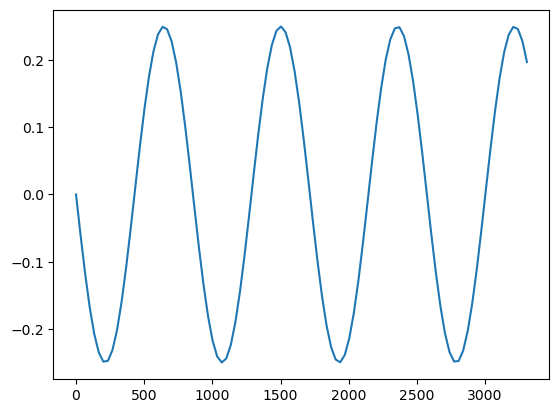

In [ ]:
x = np.linspace(100, 450, 100) * 1e3  # m
t = np.linspace(0, five_periods, 100)  # s
A = 0.25

wave = A * np.sin(kz_1D * (0 - c * t))
plt.plot(t, wave)

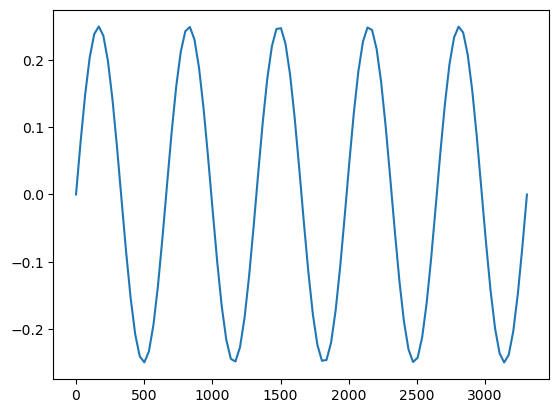

In [55]:
wave = A * np.sin(omega * t)
plt.plot(t, wave)

In [64]:
2 * np.pi / (1 / (2 * H)) / 1e3

502.2923331143374

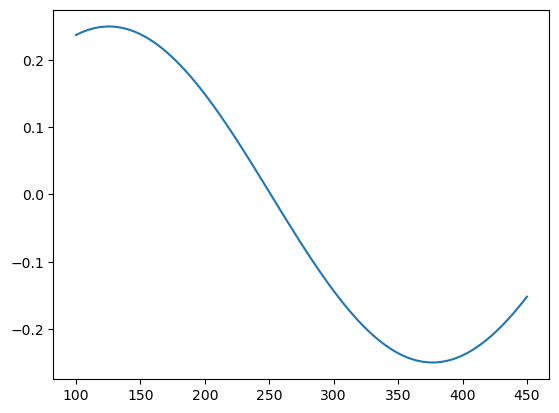

In [ ]:
F_z = A * np.sin(x / (2 * H))

plt.plot(x / 1e3, F_z)